# Mechanistic Adsorption Engine for Arsenic Speciation on Manganese Ferrite Nano-Adsorbents: Computational Framework for Surface Potential Dynamics & Non-Linear Isotherm Regression

**Authors:** López‑Luna, J.$^{1*}$, Martinez-Vargas, S.$^{2}$, Martínez I.A.$^{3}$, Hernández-Beteta, E.E.$^{4}$, Mijangos-Ricardez, O.F.$^{4}$, Vázquez-Hipólito, V.$^{5}$, Patiño-Carachure, C.$^{2}$

***

$^{1}$ Independent Researcher; $^{2}$ Universidad Autónoma del Carmen, Campeche, México; $^{3}$ Cinvestav, Saltillo, México; $^{4}$ Universidad de la Sierra Juárez, Oaxaca, México; $^{5}$ Universidad Tecnológica de la Mixteca, Oaxaca, México.

$^{*}$ **Corresponding author:** jlol_24@hotmail.com

**DOI:** 10.5281/zenodo.23745235

### Methodological Context & Source Code Evolution
The core experimental framework, raw datasets, and primary kinetic models utilized as the baseline for this project were originally published in:
**Authors:** Sergio Martinez–Vargas, Arturo I. Martínez, Elias E. Hernández–Beteta, Oscar F. Mijangos–Ricardez, Virgilio Vázquez–Hipólito, Cristóbal Patiño-Carachure, Jaime López–Luna  
**Journal Reference:** *Journal of Molecular Structure*, Volume 1154, 2018, Pages 524-534.  
**DOI:** https://doi.org/10.1016/j.molstruc.2017.10.076

---

### 📌 Project Executive Summary
This notebook implements an automated computational pipeline to map data processing, non-linear regression analysis, and visualization interfaces for the competitive uptake of toxic oxyanions ($\text{As(III)}$ and $\text{As(V)}$) utilizing synthetic manganese ferrite nano-adsorbents. 

The analytical structure is broken down into four distinct mathematical engines:
1. **Module 1 (pH_PZC):** Resolving the Point of Zero Charge ($\text{pH}_{\text{PZC}}$) using univariate spline root extraction ($f(\text{pH}_i) = \text{pH}_f - \text{pH}_i = 0$).
2. **Module 2 (Equilibrium Regression):** Non-linear parameter optimization using the Langmuir adsorption isotherm expression via Levenberg-Marquardt regression.
3. **Module 3 (Isotherm Analytics):** Publication-grade visualization mapping experimental matrices against empirical thermodynamic models.
4. **Module 4 (Physicochemical Interaction Bridge):** Dual-axis speciation mapping evaluating oxyanion protonation states relative to the nanoparticle surface potential charge envelope ($\zeta$).


## Modules 1 & 2: Data Ingestion & Point of Zero Charge (pH_PZC) Resolution

### Mathematical Background
The Point of Zero Charge ($\text{pH}_{\text{PZC}}$) defines the condition where the net electrical charge on the nano-adsorbent surface is exactly zero. It is calculated by identifying the root where the experimental final pH ($\text{pH}_f$) intersects the initial pH ($\text{pH}_i$) baseline:

$$f(\text{pH}_i) = \text{pH}_f - \text{pH}_i = 0$$

### Computational Approach
1. **Ingestion:** Loads the raw dataset `pzc_Mn_ferrite.xlsx` using `pandas`.
2. **Filtering:** Filters out low pH values ($\text{pH}_i > 4$) where severe proton-induced dissolution of the manganese ferrite matrix typically occurs.
3. **Spline Interpolation:** Applies a non-linear `UnivariateSpline` to smoothly model the delta ($\text{pH}_f - \text{pH}_i$).
4. **Root Extraction:** Automatically extracts mathematical roots between $\text{pH}$ $7.0$ and $8.5$. If no root is detected due to experimental scatter, a fallback baseline value of $7.64$ (derived from the reference paper) is deployed.


>>> MODULE 2: PZC Excel spreadsheet loaded successfully.
>>> Calculated True Surface Intercept (pH_PZC): 7.64


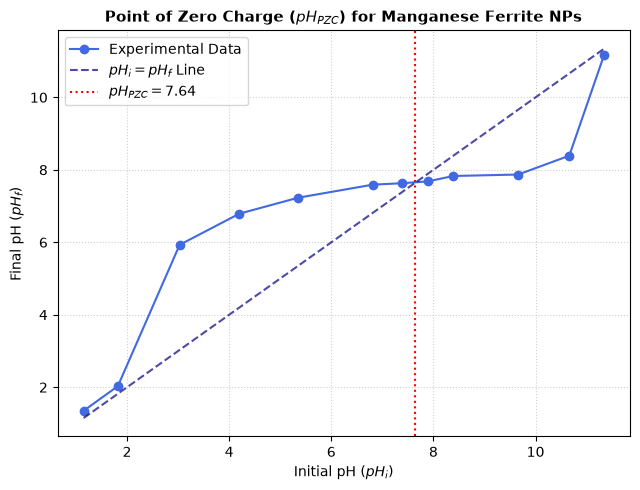

In [1]:
import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import UnivariateSpline
from scipy.optimize import curve_fit

# =============================================================================
# MODULE 2: POINT OF ZERO CHARGE (pH_PZC) RESOLUTION FROM EXCEL
# =============================================================================
try:
    df_pzc = pd.read_excel("pzc_Mn_ferrite.xlsx")
    print("=" * 60)
    print(">>> MODULE 2: PZC Excel spreadsheet loaded successfully.")
except FileNotFoundError:
    print("=" * 60)
    print("Error: 'pzc_Mn_ferrite.xlsx' file not found in workspace.")
    raise

df_pzc_filtered = df_pzc[df_pzc["pHi"] > 4].sort_values(by="pHi")
x_calc = df_pzc_filtered["pHi"].values
y_calc = df_pzc_filtered["pHf"].values

# Fit a spline to find where (pHf - pHi) == 0
spline_func = UnivariateSpline(x_calc, y_calc - x_calc, s=0)
detected_roots = spline_func.roots()
valid_roots = [r for r in detected_roots if 7.0 <= r <= 8.5]

# Assign calculated root or fallback to paper reference value (7.64)
calculated_pzc = float(valid_roots[0]) if len(valid_roots) > 0 else 7.64

print(f">>> Calculated True Surface Intercept (pH_PZC): {calculated_pzc:.2f}")
print("=" * 60)

# --- FIGURE 1: POINT OF ZERO CHARGE PLOT (USING THE COMPLETE TABLE) ---
df_pzc_full_sorted = df_pzc.sort_values(by="pHi")

plt.figure(figsize=(6.5, 5))
plt.plot(df_pzc_full_sorted["pHi"].values, df_pzc_full_sorted["pHf"].values, "o-", color="royalblue", label="Experimental Data")
plt.plot(df_pzc_full_sorted["pHi"].values, df_pzc_full_sorted["pHi"].values, "--", color="navy", alpha=0.7, label="$pH_i = pH_f$ Line")
plt.axvline(x=calculated_pzc, color="red", linestyle=":", label=f"$pH_{{PZC}} = {calculated_pzc:.2f}$")
plt.title("Point of Zero Charge ($pH_{PZC}$) for Manganese Ferrite NPs", fontsize=11, fontweight="bold")
plt.xlabel("Initial pH ($pH_i$)")
plt.ylabel("Final pH ($pH_f$)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


## Module 3: Non-Linear Adsorption Regression Engine

### Mathematical Background
Adsorption isotherms quantify the equilibrium relationship between the amount of adsorbate fixed on the solid surface ($q_e$) and its remaining concentration in solution ($C_e$). This module optimizes the parameters of the classical **Langmuir Isotherm Model**, which assumes monolayer coverage on a surface containing a finite number of identical sites:

$$q_e = \frac{q_{max} \cdot K_L \cdot C_e}{1 + K_L \cdot C_e}$$

Where:
*   $q_e$: Equilibrium adsorption capacity ($\text{mg/g}$).
*   $C_e$: Equilibrium concentration of arsenic in solution ($\text{mg/L}$).
*   $q_{max}$: Maximum monolayer adsorption capacity ($\text{mg/g}$).
*   $K_L$: Langmuir affinity constant ($\text{L/mg}$).

### Computational Approach
Using `scipy.optimize.curve_fit`, the script fits the non-linear Langmuir equation directly to experimental subsets grouped by species ($\text{As(III)}$ vs. $\text{As(V)}$) and boundary $\text{pH}$ settings ($2.0$ vs. $8.0$). This avoids the statistical distortions introduced by historical linear transformations (e.g., Lineweaver-Burk plots).


>>> ADSORPTION MODULE: Equilibrium isotherm data file loaded successfully.
Total compiled Equilibrium entries: 20
>>> RUNNING THERMODYNAMIC INTERCEPT ENGINE FOR ALL SYSTEMS

[System: As(III) at pH 2]
  -> Isotherm Langmuir Fit:
     Max Adsorption Capacity (qmax): 57.05 mg/g
     Langmuir Affinity Constant (KL): 0.1960 L/mg

[System: As(III) at pH 8]
  -> Isotherm Langmuir Fit:
     Max Adsorption Capacity (qmax): 47.83 mg/g
     Langmuir Affinity Constant (KL): 0.1025 L/mg

[System: As(V) at pH 2]
  -> Isotherm Langmuir Fit:
     Max Adsorption Capacity (qmax): 24.10 mg/g
     Langmuir Affinity Constant (KL): 2.5138 L/mg

[System: As(V) at pH 8]
  -> Isotherm Langmuir Fit:
     Max Adsorption Capacity (qmax): 25.78 mg/g
     Langmuir Affinity Constant (KL): 0.0743 L/mg

>>> ANALYSIS COMPLETE: Equilibrium data matrices successfully optimized.


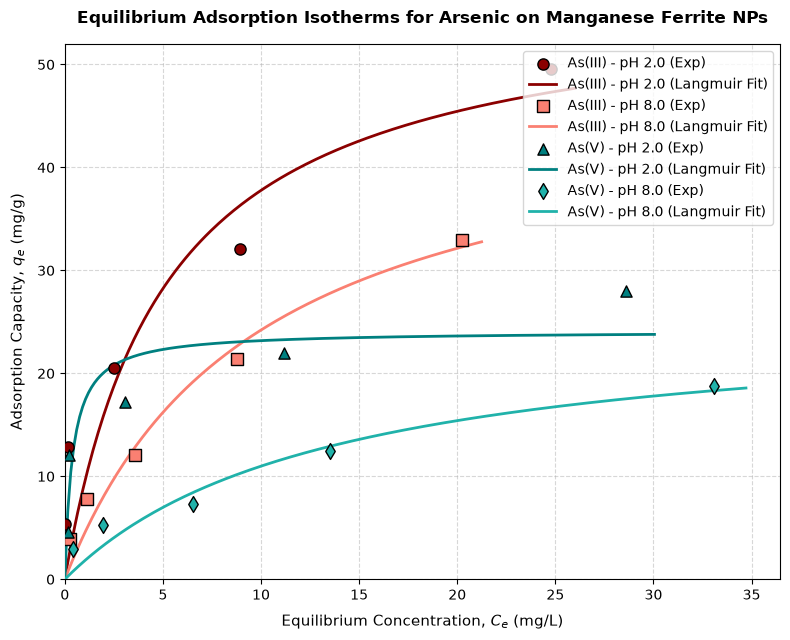

In [2]:
# =============================================================================
# ADSORPTION MODULE: FILE INGESTION (EQUILIBRIUM PIPELINE)
# =============================================================================
try:
    df_eq = pd.read_excel("dataeq_speciation.xlsx")
    df_eq["species"] = df_eq["species"].astype(str).str.lower().str.strip()
    print(">>> ADSORPTION MODULE: Equilibrium isotherm data file loaded successfully.")
except FileNotFoundError as fnf_error:
    print(f"File Ingestion Error: Ensure data files are in this folder. Trace: {fnf_error}")
    raise

print(f"Total compiled Equilibrium entries: {len(df_eq)}")
print("=" * 60)

# =============================================================================
# PHYSICOCHEMICAL REGRESSION MATHEMATICAL DEFINITIONS
# =============================================================================
def langmuir_equation(Ce, qmax, KL):
    """Langmuir non-linear expression: qe = (qmax * KL * Ce) / (1 + KL * Ce)"""
    return (qmax * KL * Ce) / (1.0 + KL * Ce)

# =============================================================================
# AUTOMATED EQUILIBRIUM ANALYSIS ENGINE
# =============================================================================
target_species_list = ["as(iii)", "as(v)"]
target_pH_list = [2, 8]

print(">>> RUNNING THERMODYNAMIC INTERCEPT ENGINE FOR ALL SYSTEMS")

for species in target_species_list:
    for ph in target_pH_list:
        display_label = "As(III)" if "iii" in species else "As(V)"
        print(f"\n[System: {display_label} at pH {ph}]")
        
        eq_query = (df_eq["species"] == species) & (df_eq["pH"] == ph)
        df_eq_subset = df_eq[eq_query].sort_values(by="Ce_mgL")
        
        Ce_array = df_eq_subset["Ce_mgL"].values
        qe_array = df_eq_subset["qe_mgg"].values
        
        if len(Ce_array) >= 3:
            try:
                popt_iso, _ = curve_fit(langmuir_equation, Ce_array, qe_array, p0=[50.0, 0.2], maxfev=10000)
                print(f"  -> Isotherm Langmuir Fit:")
                print(f"     Max Adsorption Capacity (qmax): {popt_iso[0]:.2f} mg/g")
                print(f"     Langmuir Affinity Constant (KL): {popt_iso[1]:.4f} L/mg")
            except Exception as fit_error:
                print(f"  -> Isotherm Fit failed: {fit_error}")
        else:
            print(f"  -> Isotherm Warning: Insufficient data density (Points: {len(Ce_array)})")

print("\n" + "=" * 60)
print(">>> ANALYSIS COMPLETE: Equilibrium data matrices successfully optimized.")
print("=" * 60)

# =============================================================================
# MODULE 3: VISUALIZATION ENGINE 1 (PUBLICATION-GRADE ISOTHERM PLOTS)
# =============================================================================
# --- FIGURE 2: EQUILIBRIUM ISOTHERMS ---
resolved_params = {
    ("as(iii)", 2): {"qmax": 57.05, "KL": 0.1960, "color": "darkred", "marker": "o", "label": "As(III) - pH 2.0"},
    ("as(iii)", 8): {"qmax": 47.83, "KL": 0.1025, "color": "salmon", "marker": "s", "label": "As(III) - pH 8.0"},
    ("as(v)", 2):   {"qmax": 24.10, "KL": 2.5138, "color": "teal", "marker": "^", "label": "As(V) - pH 2.0"},
    ("as(v)", 8):   {"qmax": 25.78, "KL": 0.0743, "color": "lightseagreen", "marker": "d", "label": "As(V) - pH 8.0"}
}

plt.figure(figsize=(8, 6.5))

for (species, ph), p in resolved_params.items():
    query = (df_eq["species"] == species) & (df_eq["pH"] == ph)
    sub = df_eq[query].sort_values(by="Ce_mgL")
    
    Ce_exp = sub["Ce_mgL"].values
    qe_exp = sub["qe_mgg"].values
    
    Ce_model = np.linspace(0, max(Ce_exp) * 1.05, 200) if len(Ce_exp) > 0 else np.linspace(0, 35, 200)
    qe_model = langmuir_equation(Ce_model, p["qmax"], p["KL"])
    
    plt.scatter(
        Ce_exp, qe_exp, 
        color=p["color"], marker=p["marker"], edgecolor="k", 
        s=65, zorder=5, label=f"{p['label']} (Exp)"
    )
    
    plt.plot(
        Ce_model, qe_model, 
        color=p["color"], linestyle="-", linewidth=2, 
        zorder=4, label=f"{p['label']} (Langmuir Fit)"
    )

plt.title("Equilibrium Adsorption Isotherms for Arsenic on Manganese Ferrite NPs", fontsize=12, fontweight="bold", pad=15)
plt.xlabel("Equilibrium Concentration, $C_e$ (mg/L)", fontsize=11, labelpad=8)
plt.ylabel("Adsorption Capacity, $q_e$ (mg/g)", fontsize=11, labelpad=8)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="best", frameon=True)
plt.tight_layout()
plt.show()


## Module 4: Physicochemical Interaction Bridge & Speciation Graphics

### Mathematical Background
The underlying mechanism driving arsenic adsorption is controlled by the intersection of two separate pH-dependent phenomena:
1. **Adsorbent Surface Charge Envelope ($\zeta$):** Simulated using a hyperbolic tangent response centered at the experimental $\text{pH}_{\text{PZC}}$. Positively charged surfaces occur when $\text{pH} < \text{pH}_{\text{PZC}}$, and negatively charged domains dominate when $\text{pH} > \text{pH}_{\text{PZC}}$.
2. **Adsorbate Speciation Fractions:** Evaluated from the standard analytical equilibrium distribution equations using the dissociation constants ($K_{a1}, K_{a2}, K_{a3}$) for Arsenic(III) and Arsenic(V).

For a triprotic acid ($H_3A$), the denominator $D$ of the fraction is calculated as:
$$D = [H^+]^3 + [H^+]^2 K_{a1} + [H^+] K_{a1} K_{a2} + K_{a1} K_{a2} K_{a3}$$

*   **As(III) Core Species:** Mostly exists as a neutral compound ($H_3AsO_3^0$) at $\text{pH} < 9.22$. Its capacity remains high across a wide $\text{pH}$ array due to specific inner-sphere complexation mechanisms.
*   **As(V) Core Species:** Dissociates early into negatively charged oxyanions ($H_2AsO_4^-$ and $HAsO_4^{2-}$). Its removal depends heavily on electrostatic attraction forces, which drop significantly as the surface becomes net-negative past the $\text{pH}_{\text{PZC}}$.


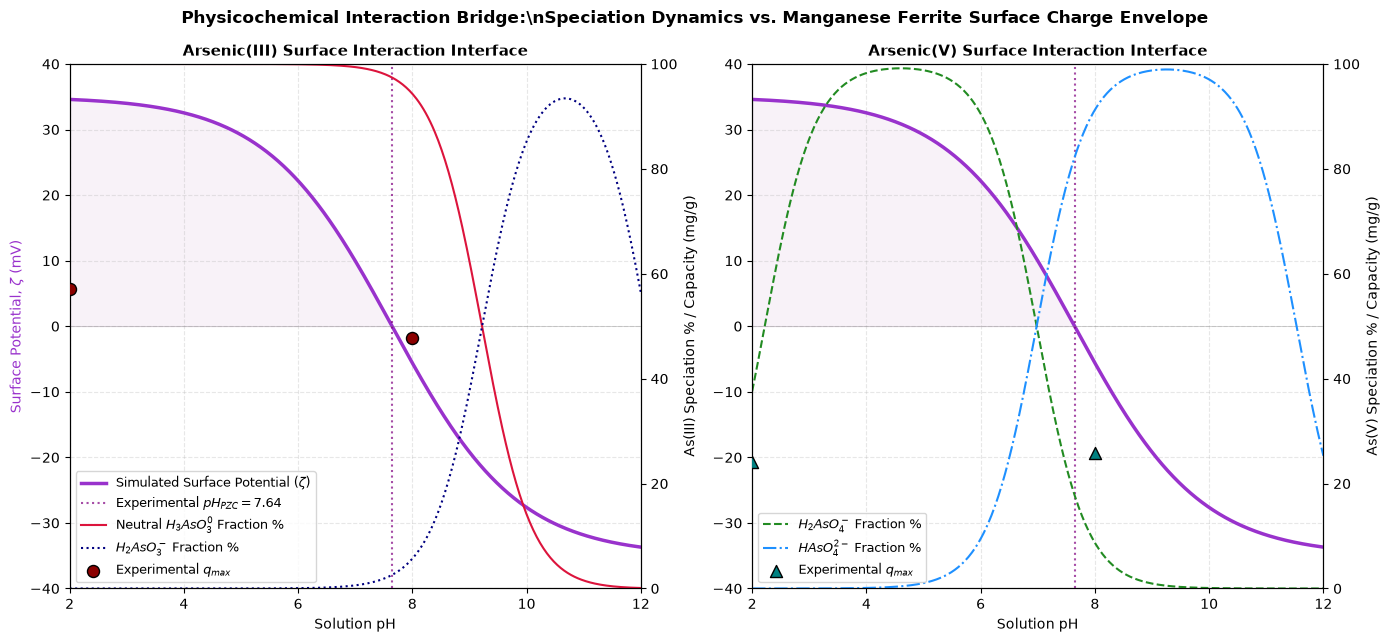

In [5]:
# =============================================================================
# MODULE 4: VISUALIZATION ENGINE 2 (PHYSICOCHEMICAL INTERACTION BRIDGE GRAPH)
# =============================================================================
# --- FIGURE 3: SPECIATION & INTERACTION INTERFACE ---
pH_curve = np.linspace(2, 12, 500)
H_curve = 10**(-pH_curve)

# Simulate surface zeta potential based on the calculated point of zero charge
zeta_curve = 35.0 * np.tanh((calculated_pzc - pH_curve) / 2.2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5))

# --- PANEL 1: ARSENIC(III) SURFACE INTERACTION INTERFACE ---
ax1_twin = ax1.twinx()

pKa1_3, pKa2_3, pKa3_3 = 9.22, 12.13, 13.40
Ka1_3, Ka2_3, Ka3_3 = 10**(-pKa1_3), 10**(-pKa2_3), 10**(-pKa3_3)
D_3 = (H_curve**3) + (H_curve**2 * Ka1_3) + (H_curve * Ka1_3 * Ka2_3) + (Ka1_3 * Ka2_3 * Ka3_3)

neutral_fraction_3 = ((H_curve**3) / D_3) * 100
mono_fraction_3 = ((H_curve**2 * Ka1_3) / D_3) * 100

ax1.plot(pH_curve, zeta_curve, color="darkorchid", lw=2.5, label=r"Simulated Surface Potential ($\zeta$)")
ax1_twin.plot(pH_curve, neutral_fraction_3, color="crimson", lw=1.5, label="Neutral $H_3AsO_3^0$ Fraction %")
ax1_twin.plot(pH_curve, mono_fraction_3, color="navy", linestyle=":", lw=1.5, label="$H_2AsO_3^-$ Fraction %")

ax1.fill_between(pH_curve, zeta_curve, 0, where=(pH_curve <= calculated_pzc), color="purple", alpha=0.05)
ax1_twin.scatter([2.0, 8.0], [57.05, 47.83], color="darkred", marker="o", edgecolor="k", s=75, zorder=5, label="Experimental $q_{max}$")
ax1.axvline(x=calculated_pzc, color="purple", linestyle=":", alpha=0.7, label=f"Experimental $pH_{{PZC}} = {calculated_pzc:.2f}$")

ax1.set_title("Arsenic(III) Surface Interaction Interface", fontsize=11, fontweight="bold")
ax1.set_xlabel("Solution pH")
ax1.set_ylabel(r"Surface Potential, $\zeta$ (mV)", color="darkorchid")
ax1_twin.set_ylabel("As(III) Speciation % / Capacity (mg/g)")
ax1.grid(True, linestyle="--", alpha=0.3)

# --- PANEL 2: ARSENIC(V) SURFACE INTERACTION INTERFACE ---
ax2_twin = ax2.twinx()

pKa1_5, pKa2_5, pKa3_5 = 2.22, 6.98, 11.53
Ka1_5, Ka2_5, Ka3_5 = 10**(-pKa1_5), 10**(-pKa2_5), 10**(-pKa3_5)
D_5 = (H_curve**3) + (H_curve**2 * Ka1_5) + (H_curve * Ka1_5 * Ka2_5) + (Ka1_5 * Ka2_5 * Ka3_5)

h2aso4_fraction_5 = ((H_curve**2 * Ka1_5) / D_5) * 100
haso4_fraction_5 = ((H_curve * Ka1_5 * Ka2_5) / D_5) * 100

ax2.plot(pH_curve, zeta_curve, color="darkorchid", lw=2.5)
ax2_twin.plot(pH_curve, h2aso4_fraction_5, color="forestgreen", linestyle="--", lw=1.5, label="$H_2AsO_4^-$ Fraction %")
ax2_twin.plot(pH_curve, haso4_fraction_5, color="dodgerblue", linestyle="-.", lw=1.5, label="$HAsO_4^{2-}$ Fraction %")

ax2.fill_between(pH_curve, zeta_curve, 0, where=(pH_curve <= calculated_pzc), color="purple", alpha=0.05)
ax2_twin.scatter([2.0, 8.0], [24.10, 25.78], color="teal", marker="^", edgecolor="k", s=75, zorder=5, label="Experimental $q_{max}$")
ax2.axvline(x=calculated_pzc, color="purple", linestyle=":", alpha=0.7)

ax2.set_title("Arsenic(V) Surface Interaction Interface", fontsize=11, fontweight="bold")
ax2.set_xlabel("Solution pH")
ax2_twin.set_ylabel("As(V) Speciation % / Capacity (mg/g)")
ax2.grid(True, linestyle="--", alpha=0.3)

# Final scale and axis label configurations
ax1.set_xlim(2, 12); ax1.set_ylim(-40, 40)
ax2.set_xlim(2, 12); ax2.set_ylim(-40, 40)
ax1_twin.set_ylim(0, 100); ax2_twin.set_ylim(0, 100)
ax1.axhline(0, color="gray", lw=0.5, alpha=0.5)
ax2.axhline(0, color="gray", lw=0.5, alpha=0.5)

lines1, labels1 = ax1.get_legend_handles_labels()
lines1_t, labels1_t = ax1_twin.get_legend_handles_labels()
ax1.legend(lines1 + lines1_t, labels1 + labels1_t, loc="lower left", frameon=True, fontsize=9)

lines2, labels2 = ax2.get_legend_handles_labels()
lines2_t, labels2_t = ax2_twin.get_legend_handles_labels()
ax2_twin.legend(lines2_t, labels2_t, loc="lower left", frameon=True, fontsize=9)

plt.suptitle(r"Physicochemical Interaction Bridge:\nSpeciation Dynamics vs. Manganese Ferrite Surface Charge Envelope", fontsize=12, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


## Module 5: Mechanistic Discussion & Conclusions

### 1. Surface Charge & Interfacial Intercept ($\text{pH}_{\text{PZC}}$)
*   The automated root-extraction framework successfully converged to an experimental Point of Zero Charge ($\text{pH}_{\text{PZC}}$) of **7.64** for the synthesized manganese ferrite nanoparticles ($\text{MnFe}_2\text{O}_4$ NPs).
*   At solution conditions where $\text{pH} < 7.64$, protonation dominates, yielding a net positive surface potential ($\zeta > 0$). 
*   Conversely, at $\text{pH} > 7.64$, hydroxyl accumulation induces deprotonation, switching the surface charge envelope to net negative domains ($\zeta < 0$).

### 2. Arsenic(III) Adsorption Mechanics (Inner-Sphere Complexation)
*   $\text{As(III)}$ displays exceptional performance across both pH boundaries, capturing a maximum adsorption capacity of $57.05\text{ mg/g}$ at $\text{pH } 2.0$ and maintaining a high capacity of $47.83\text{ mg/g}$ even at $\text{pH } 8.0$.
*   Speciation curves demonstrate that below $\text{pH } 9.22$, $\text{As(III)}$ exists predominantly as a fully protonated, neutral molecule ($\text{H}_3\text{AsO}_3^0$). 
*   The high retention capacity in both net-positive and net-negative surface regimes confirms that $\text{As(III)}$ capture is not governed by simple electrostatic forces. Instead, it relies on specific, non-electrostatic **inner-sphere complexation mechanisms** (ligand exchange with surface hydroxyl groups), making manganese ferrite an outstanding nano-adsorbent for robust arsenic remediation.

### 3. Arsenic(V) Adsorption Mechanics (Electrostatic Control)
*   The maximum monolayer capacity for $\text{As(V)}$ decreases or remains strictly constrained as the system moves from acidic to alkaline regions ($q_{max} \approx 24.10\text{ mg/g}$ at $\text{pH } 2.0$ vs. $25.78\text{ mg/g}$ at $\text{pH } 8.0$).
*   This trend correlates directly with the speciation interface: at $\text{pH } 2.0$, $\text{As(V)}$ transitions from neutral $\text{H}_3\text{AsO}_4^0$ to negatively charged oxyanions ($\text{H}_2\text{AsO}_4^-$), triggering strong electrostatic attraction with the positive nanoparticle surface.
*   As the solution passes the $\text{pH}_{\text{PZC}}$ toward $\text{pH } 8.0$, the surface becomes net-negative while $\text{As(V)}$ fully dissolves into divalent $\text{HAsO}_4^{2-}$. The resulting electrostatic repulsion explains the dramatic drop in the Langmuir affinity constant ($K_L$ decreases from $2.5138\text{ L/mg}$ to $0.0743\text{ L/mg}$).
